# 数字123：ランク200などの低ランクでどれくらい崩れるかを見る

**50・100・200・300・450・512**を同じランク512の親基底から切り出して比較します。43モード、41本のThread、kr、係数、配置、開口、伝搬範囲0〜50 cmは固定です。

このノートブックは失敗も含めて観察する診断用です。初期複素場誤差1%・強度誤差3%の基準を超えたランクもCGH化・伝搬します。不合格を合格と扱うことはありません。通常の採用候補を選ぶノートブックの品質ガードは維持します。

直接法の場・係数・伝搬像は保存済みランク512検証の結果を参照します。直接法を各ランクで再計算しないため、新しい直接法の時間や速度比は測りません。提案法の場生成は配列配置修正版で、全ランクを1回ウォームアップ後3回計測した中央値を比較します。

画像は直接法と同じ正規化で表示します。低ランクで暗くなっても、その像だけ明るさを合わせる処理はしません。既存の200・300・450・512のCGH・伝搬結果を再利用し、追加分の50・100だけ新しく伝搬します。場生成の中央値は全6候補を同じ実行で測り直します。こちらでは研究計算を実行していません。


In [1]:
import importlib
from pathlib import Path
from IPython.display import Image, display
import lsh_digit1_theory as theory
import lsh_digit1_proposed as proposed
import lsh_digits123_rank_audit as rank_audit
import lsh_digits123_low_rank as low_rank
theory = importlib.reload(theory)
proposed = importlib.reload(proposed)
rank_audit = importlib.reload(rank_audit)
low_rank = importlib.reload(low_rank)

REFERENCE_DIR = Path('lsh_digits123_rank_verified_outputs_rank512_parent512_v1')
OUTPUT_DIR = Path('lsh_digits123_low_rank_outputs_v2_extended')
REUSE_DIR = Path('lsh_digits123_low_rank_outputs_v1')  # 完成済みCGH・伝搬を再利用
RANKS = (50, 100, 200, 300, 450, 512)  # 親基底固定のため512は残す。
TIMING_REPEATS = 3
TIMING_WARMUPS = 1
MAX_COMPLEX_ERROR = 0.01
MAX_INTENSITY_ERROR = 0.03
print('全候補をCGH・伝搬まで診断:', RANKS)
print('オンライン実装:', proposed.ONLINE_IMPLEMENTATION_VERSION)
print('品質基準を超えたランクも比較します。光量低下を隠す正規化はしません。')


全候補をCGH・伝搬まで診断: (50, 100, 200, 300, 450, 512)
オンライン実装: contiguous_core_matvec_v2
品質基準を超えたランクも比較します。光量低下を隠す正規化はしません。


In [2]:
# 全ランクの初期場・時間を測り、合否にかかわらずCGH再生を伝搬する。
# 同条件の完成結果は読み込み、中断した実行は完成済みランクから再開する。
summary = low_rank.run_low_rank_study(REFERENCE_DIR, OUTPUT_DIR, RANKS,
    max_complex_error=MAX_COMPLEX_ERROR, max_intensity_error=MAX_INTENSITY_ERROR,
    timing_repeats=TIMING_REPEATS, timing_warmups=TIMING_WARMUPS, reuse_dir=REUSE_DIR)
print('保存先:', OUTPUT_DIR.resolve())
print('各ランクの画質・時間:', (OUTPUT_DIR/'rank_comparison.csv').resolve())
print('初期評価の時間内訳:', summary['initial_audit_dir'])


Rank 50: complex error=99.088%, intensity error=99.255%, power/direct=0.0193, field median=0.1103s (3 repeats)
Rank 100: complex error=93.084%, intensity error=94.808%, power/direct=0.1335, field median=0.2259s (3 repeats)
Rank 200: complex error=19.374%, intensity error=19.085%, power/direct=0.9566, field median=0.4209s (3 repeats)
Rank 300: complex error=2.857%, intensity error=0.749%, power/direct=0.9989, field median=0.7446s (3 repeats)
Rank 450: complex error=0.790%, intensity error=0.137%, power/direct=0.9998, field median=1.4388s (3 repeats)
Rank 512: complex error=0.172%, intensity error=0.021%, power/direct=1.0000, field median=2.1023s (3 repeats)
Rank 50: diagnostic CGH/propagation, including failed initial checks
Sensor propagation: 1/251, z=0.0 mm
Sensor propagation: 13/251, z=24.0 mm
Sensor propagation: 25/251, z=48.0 mm
Sensor propagation: 37/251, z=72.0 mm
Sensor propagation: 49/251, z=96.0 mm
Sensor propagation: 61/251, z=120.0 mm
Sensor propagation: 73/251, z=144.0 mm


In [3]:
print('rank | 初期複素場誤差[%] | 再生強度誤差[%] | 再生SSIM | PSNR[dB] | パワー比 | 場生成[秒・中央値] | 初期場合格')
for row in summary['cases']:
    print(f"{row['rank']:4d} | {100*row['initial_complex_relative_l2']:17.4f} | "
          f"{100*row['cgh_replay_intensity_relative_l2']:15.4f} | {row['cgh_replay_ssim']:.7f} | "
          f"{float(row['cgh_replay_psnr_db']):8.2f} | {row['initial_power_ratio_vs_direct']:8.4f} | "
          f"{row['field_seconds_median']:20.4f} | {'合格' if row['initial_check_passed'] else '不合格・診断用'}")
print('直接法/目標の評価:', summary['direct_vs_target'])
print('CGH・伝搬を再利用したランク:', summary['reused_replay_ranks'])
print('時間は提案法の場生成。直接法の新しい時間は計測していません。')


rank | 初期複素場誤差[%] | 再生強度誤差[%] | 再生SSIM | PSNR[dB] | パワー比 | 場生成[秒・中央値] | 初期場合格
  50 |           99.0878 |         98.8202 | 0.6763365 |    11.56 |   0.0193 |               0.1103 | 不合格・診断用
 100 |           93.0843 |         94.3334 | 0.5756390 |    11.96 |   0.1335 |               0.2259 | 不合格・診断用
 200 |           19.3739 |         19.1780 | 0.8982537 |    25.80 |   0.9566 |               0.4209 | 不合格・診断用
 300 |            2.8570 |          2.7509 | 0.9951612 |    42.66 |   0.9989 |               0.7446 | 不合格・診断用
 450 |            0.7899 |          0.3843 | 0.9999169 |    59.76 |   0.9998 |               1.4388 | 合格
 512 |            0.1725 |          0.1638 | 0.9999843 |    67.17 |   1.0000 |               2.1023 | 合格
直接法/目標の評価: {'intensity_relative_l2': 0.32807586206627876, 'ssim': 0.7686011283733056, 'psnr_db': 16.97356560672406, 'snr_db': 9.680514426539856}
CGH・伝搬を再利用したランク: [200, 300, 450, 512]
時間は提案法の場生成。直接法の新しい時間は計測していません。


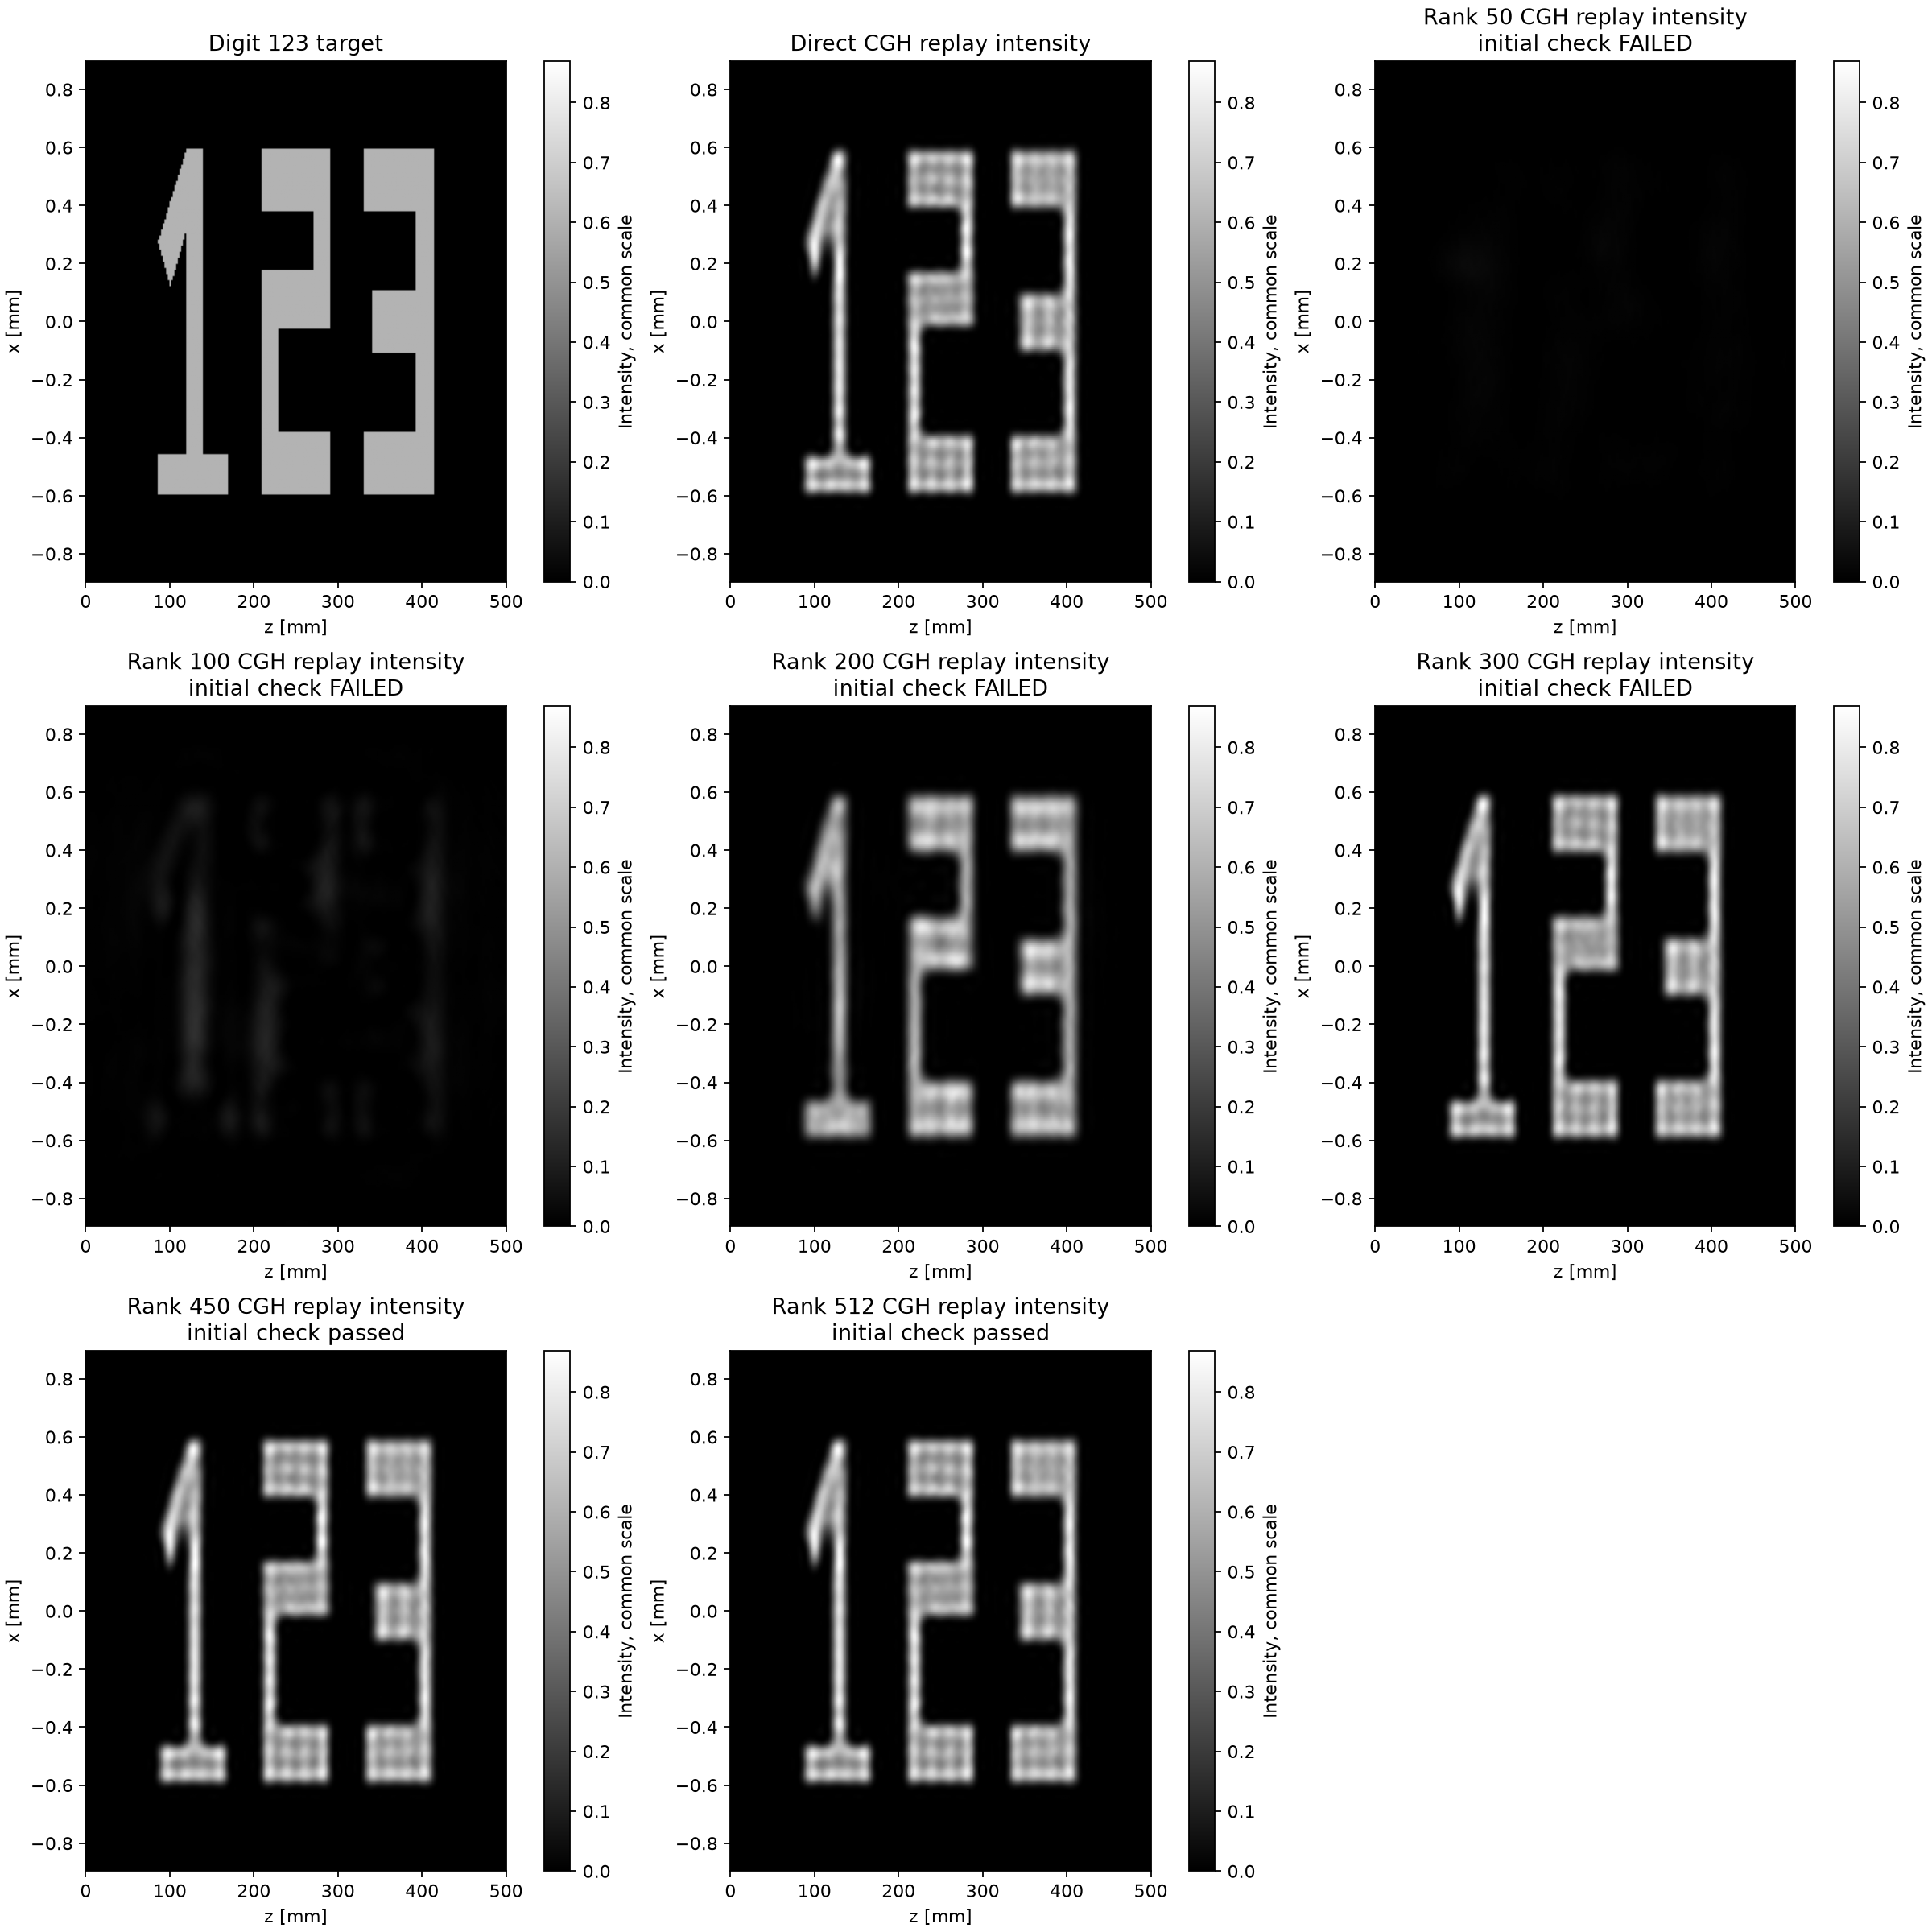

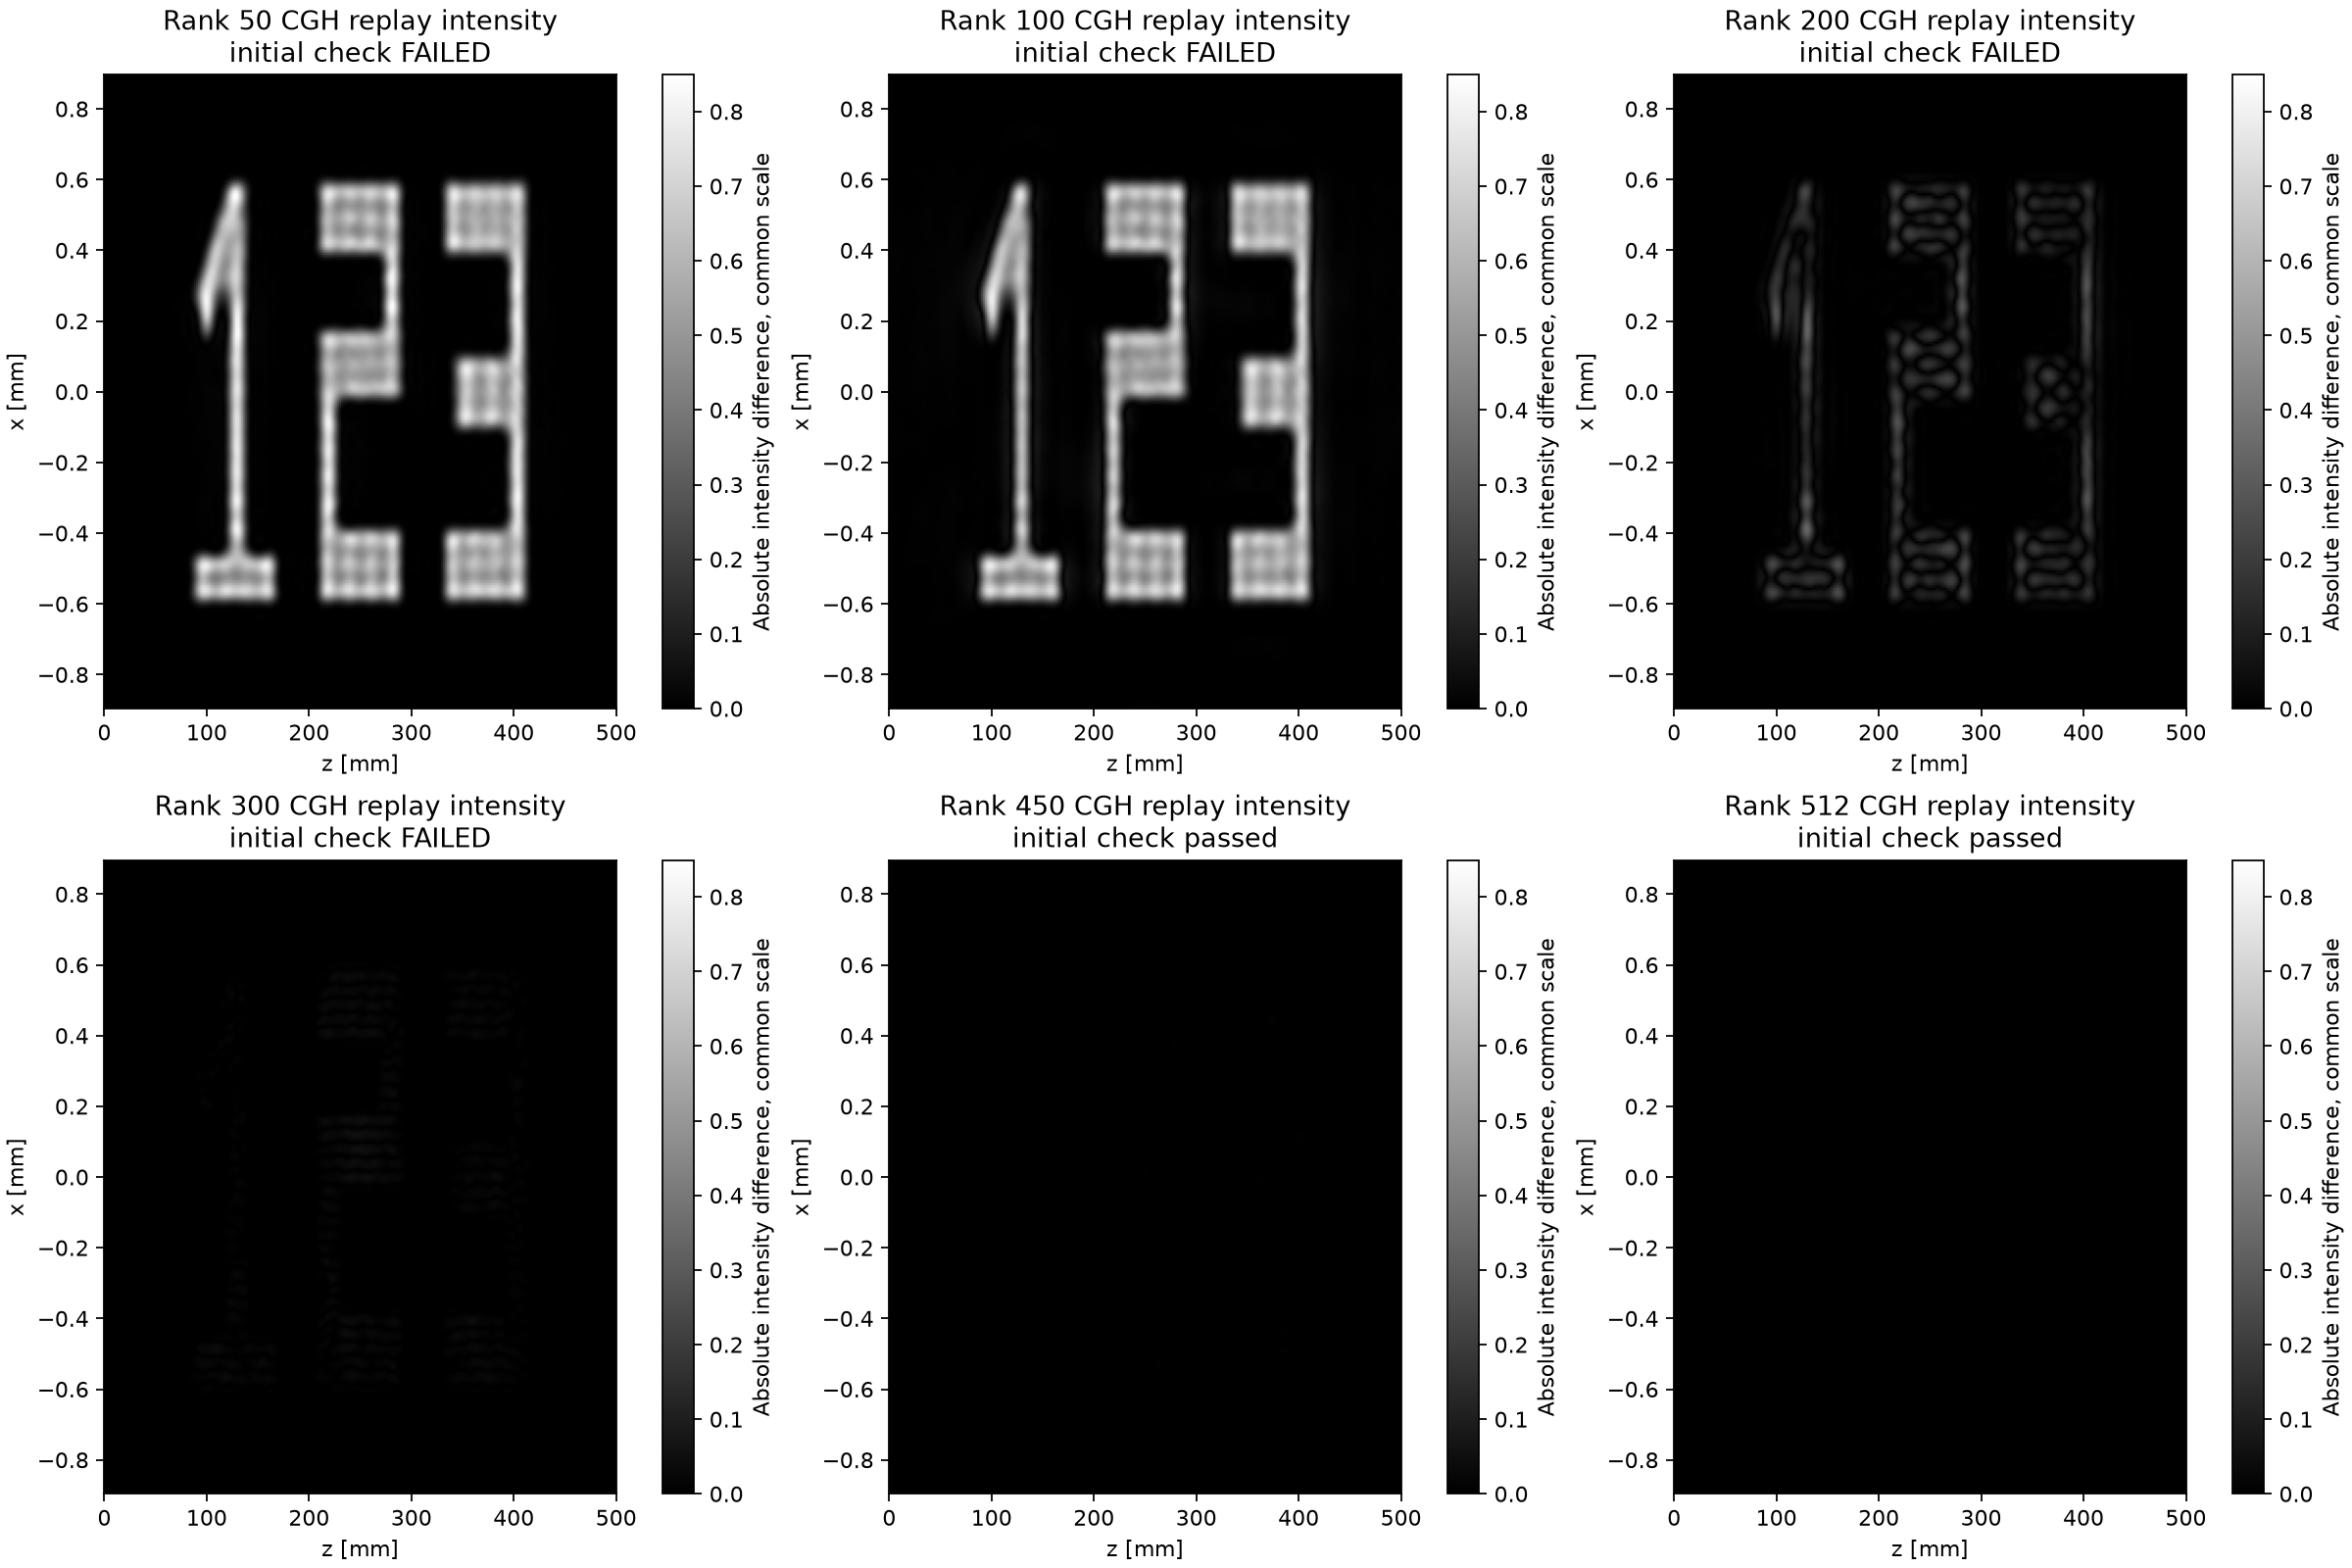

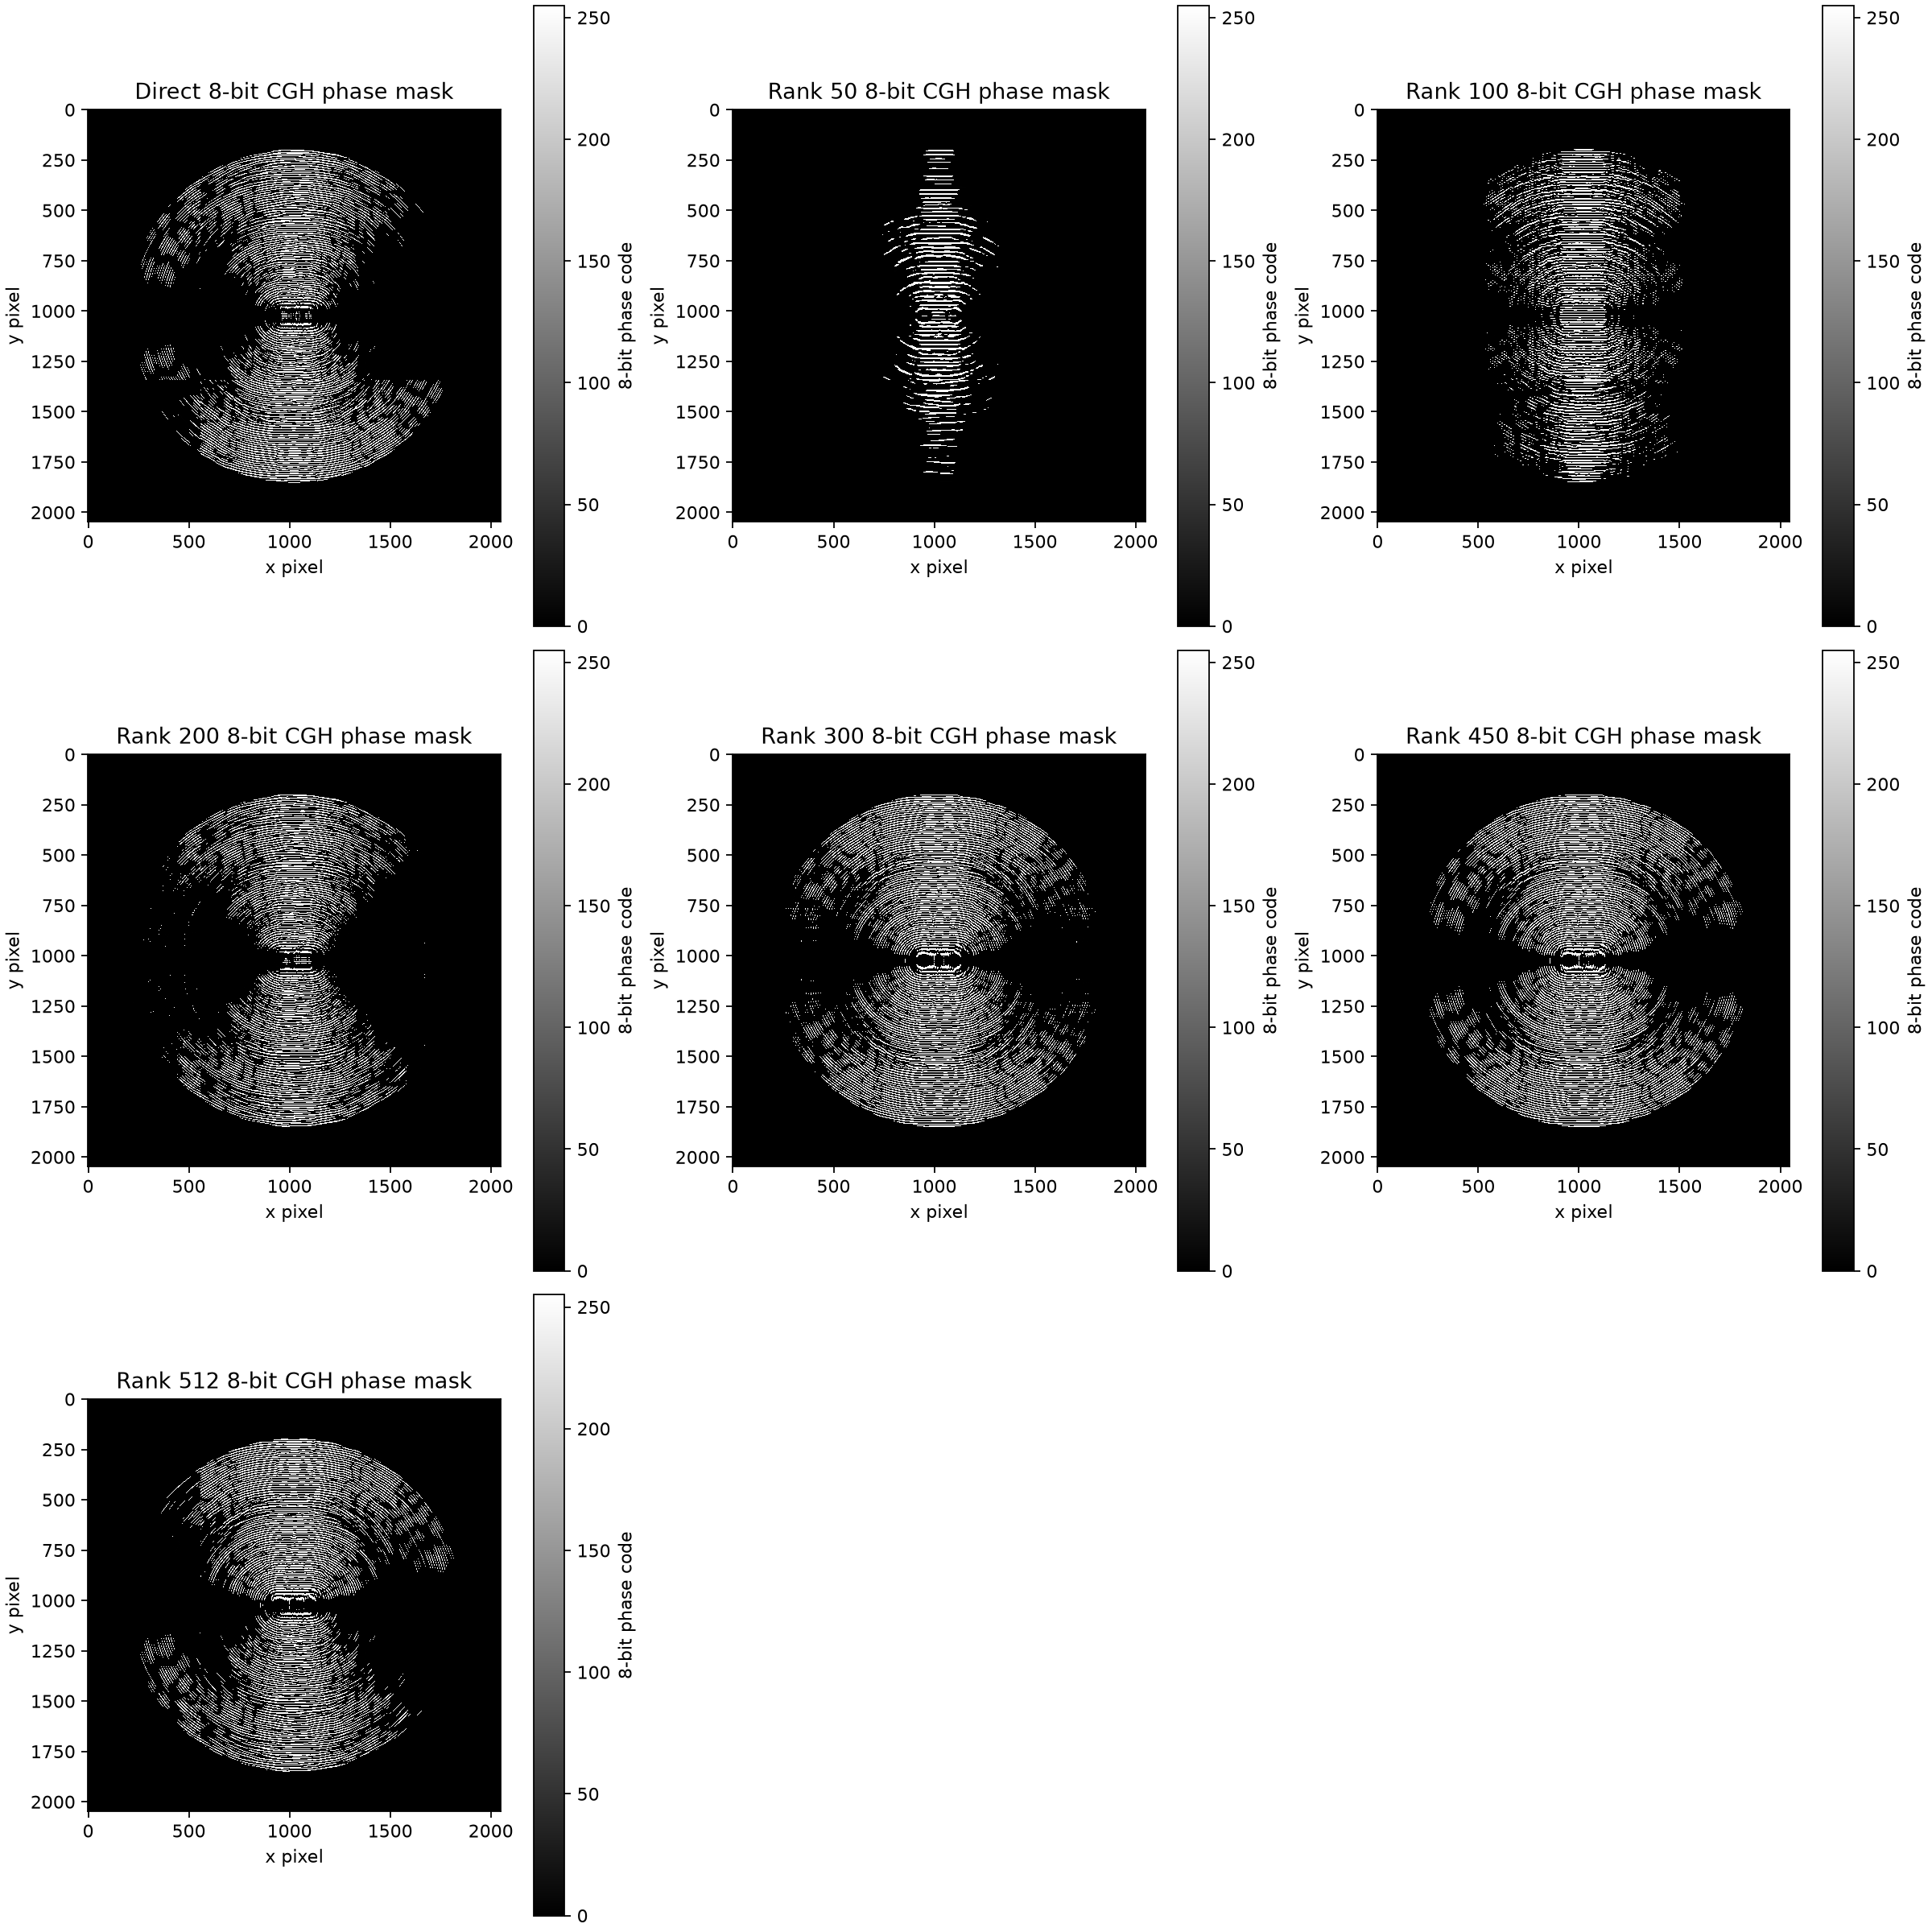

In [4]:
# 目標、直接法、各ランクの再生強度を共通の明るさで並べる。
display(Image(filename=str(OUTPUT_DIR/'cgh_replay_all_ranks.png'), width=1500))
# 直接法との差。全ランクの差分も共通スケール。
display(Image(filename=str(OUTPUT_DIR/'cgh_replay_absolute_differences.png'), width=1300))
# CGHの8-bit位相コード。上の再生強度画像とは別物。
display(Image(filename=str(OUTPUT_DIR/'cgh_masks_all_ranks.png'), width=1500))


拡大表示するランク: 50


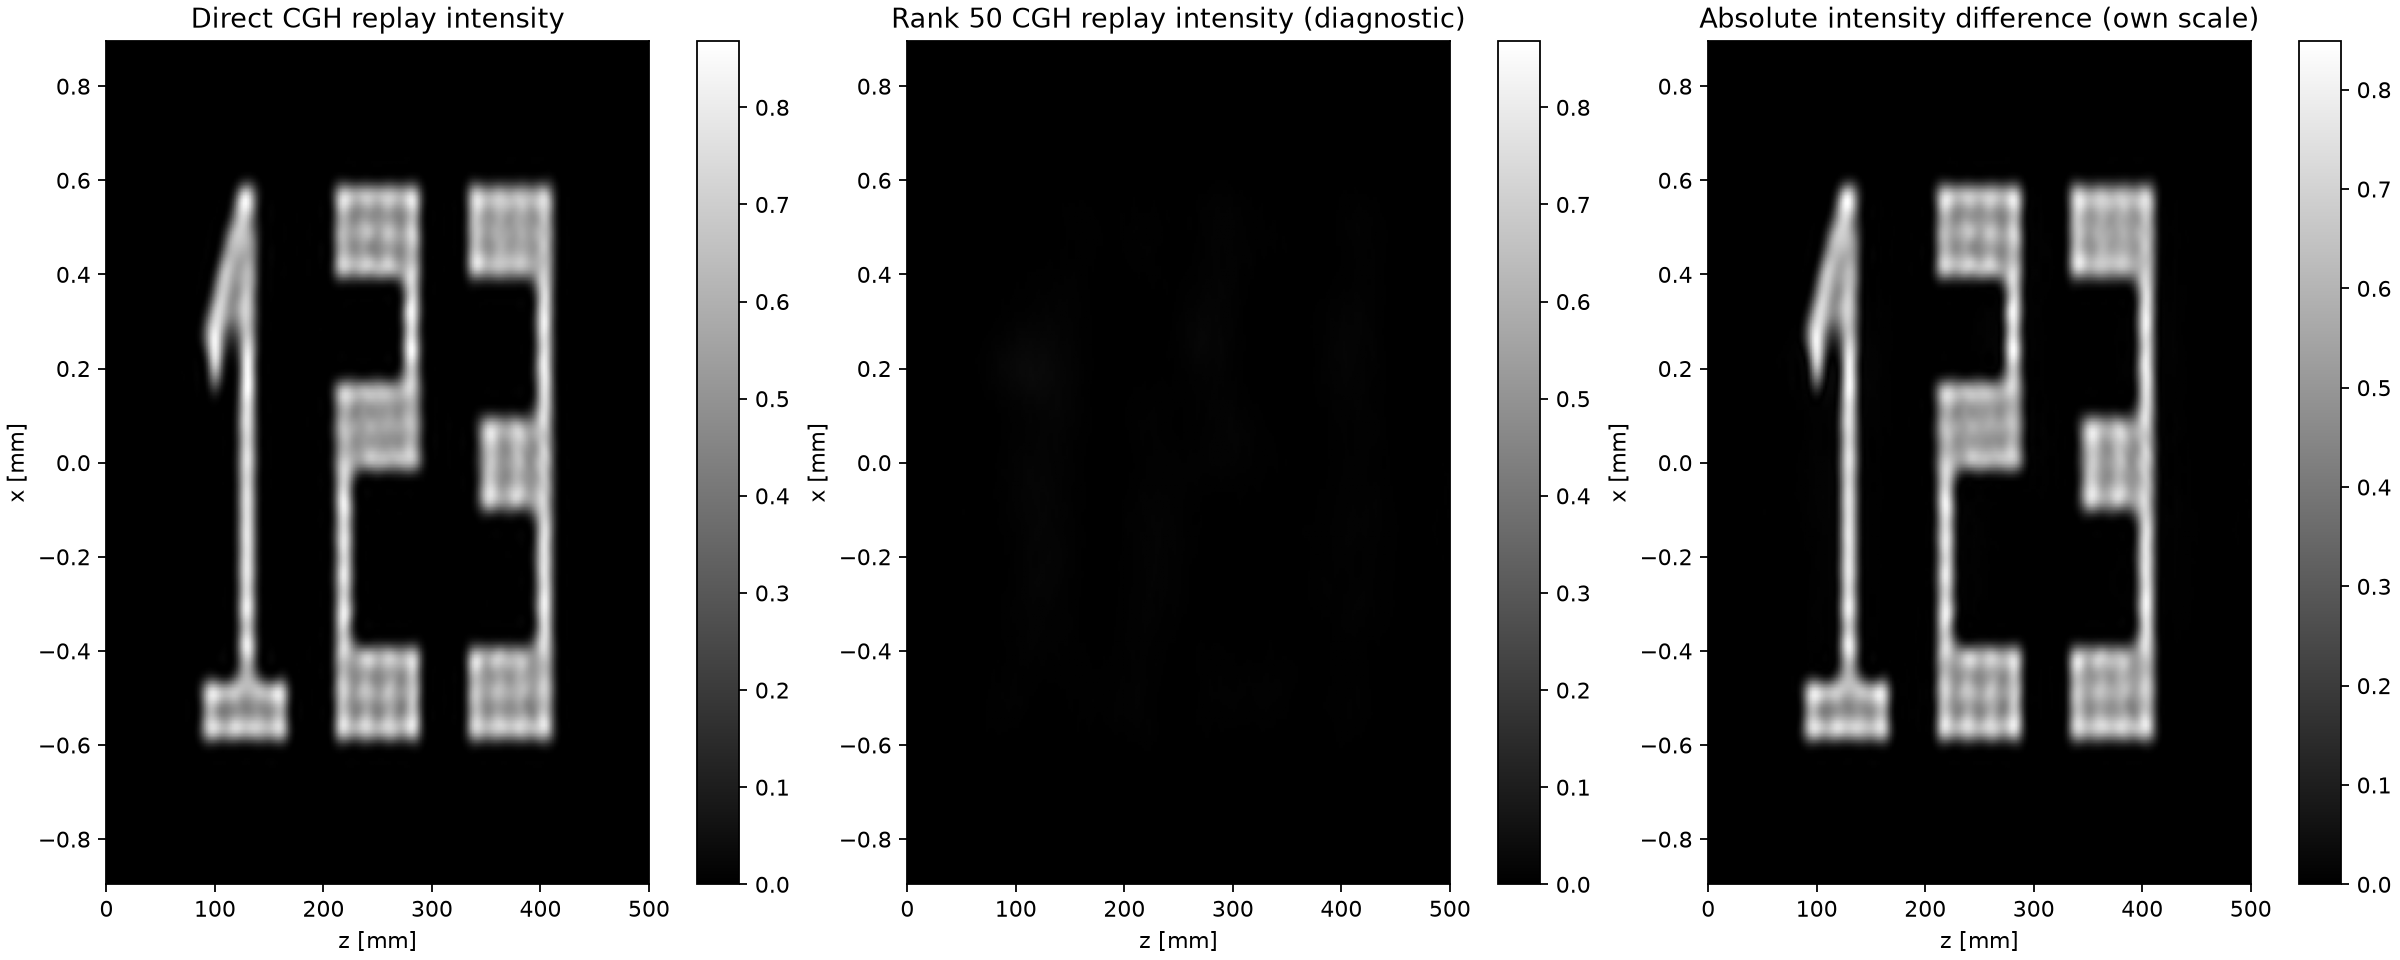

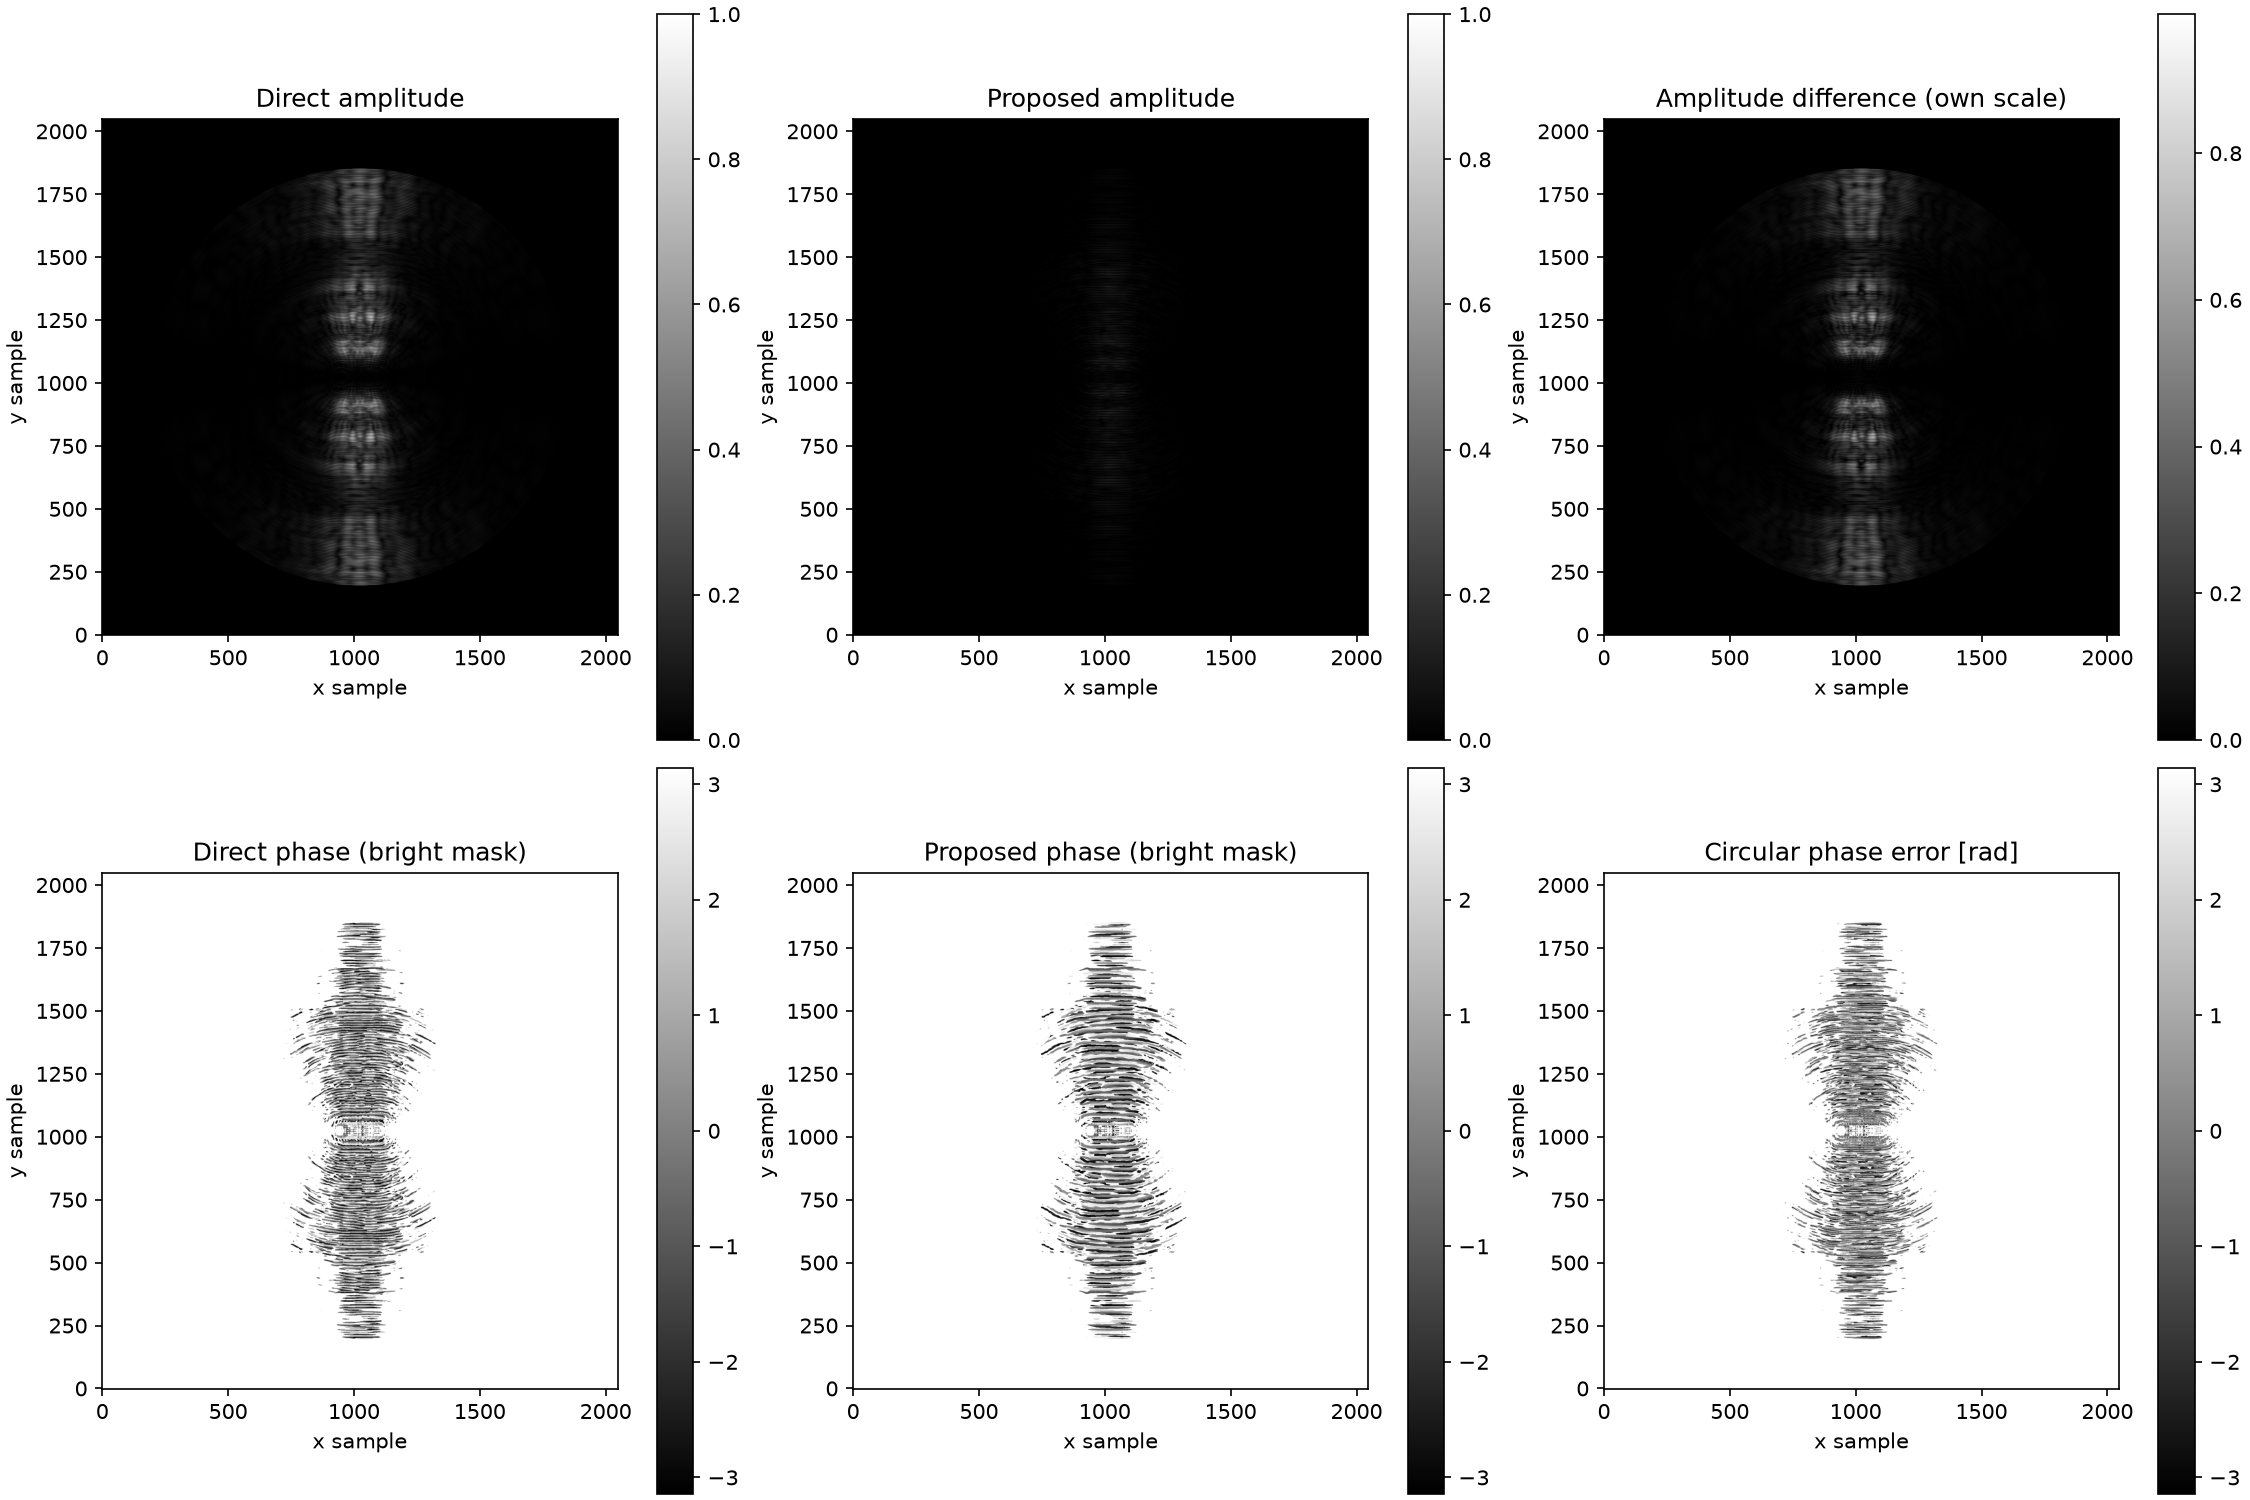

詳細: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank50\summary.json
8-bit位相マスク: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank50\proposed_cgh_8bit.png
拡大表示するランク: 100


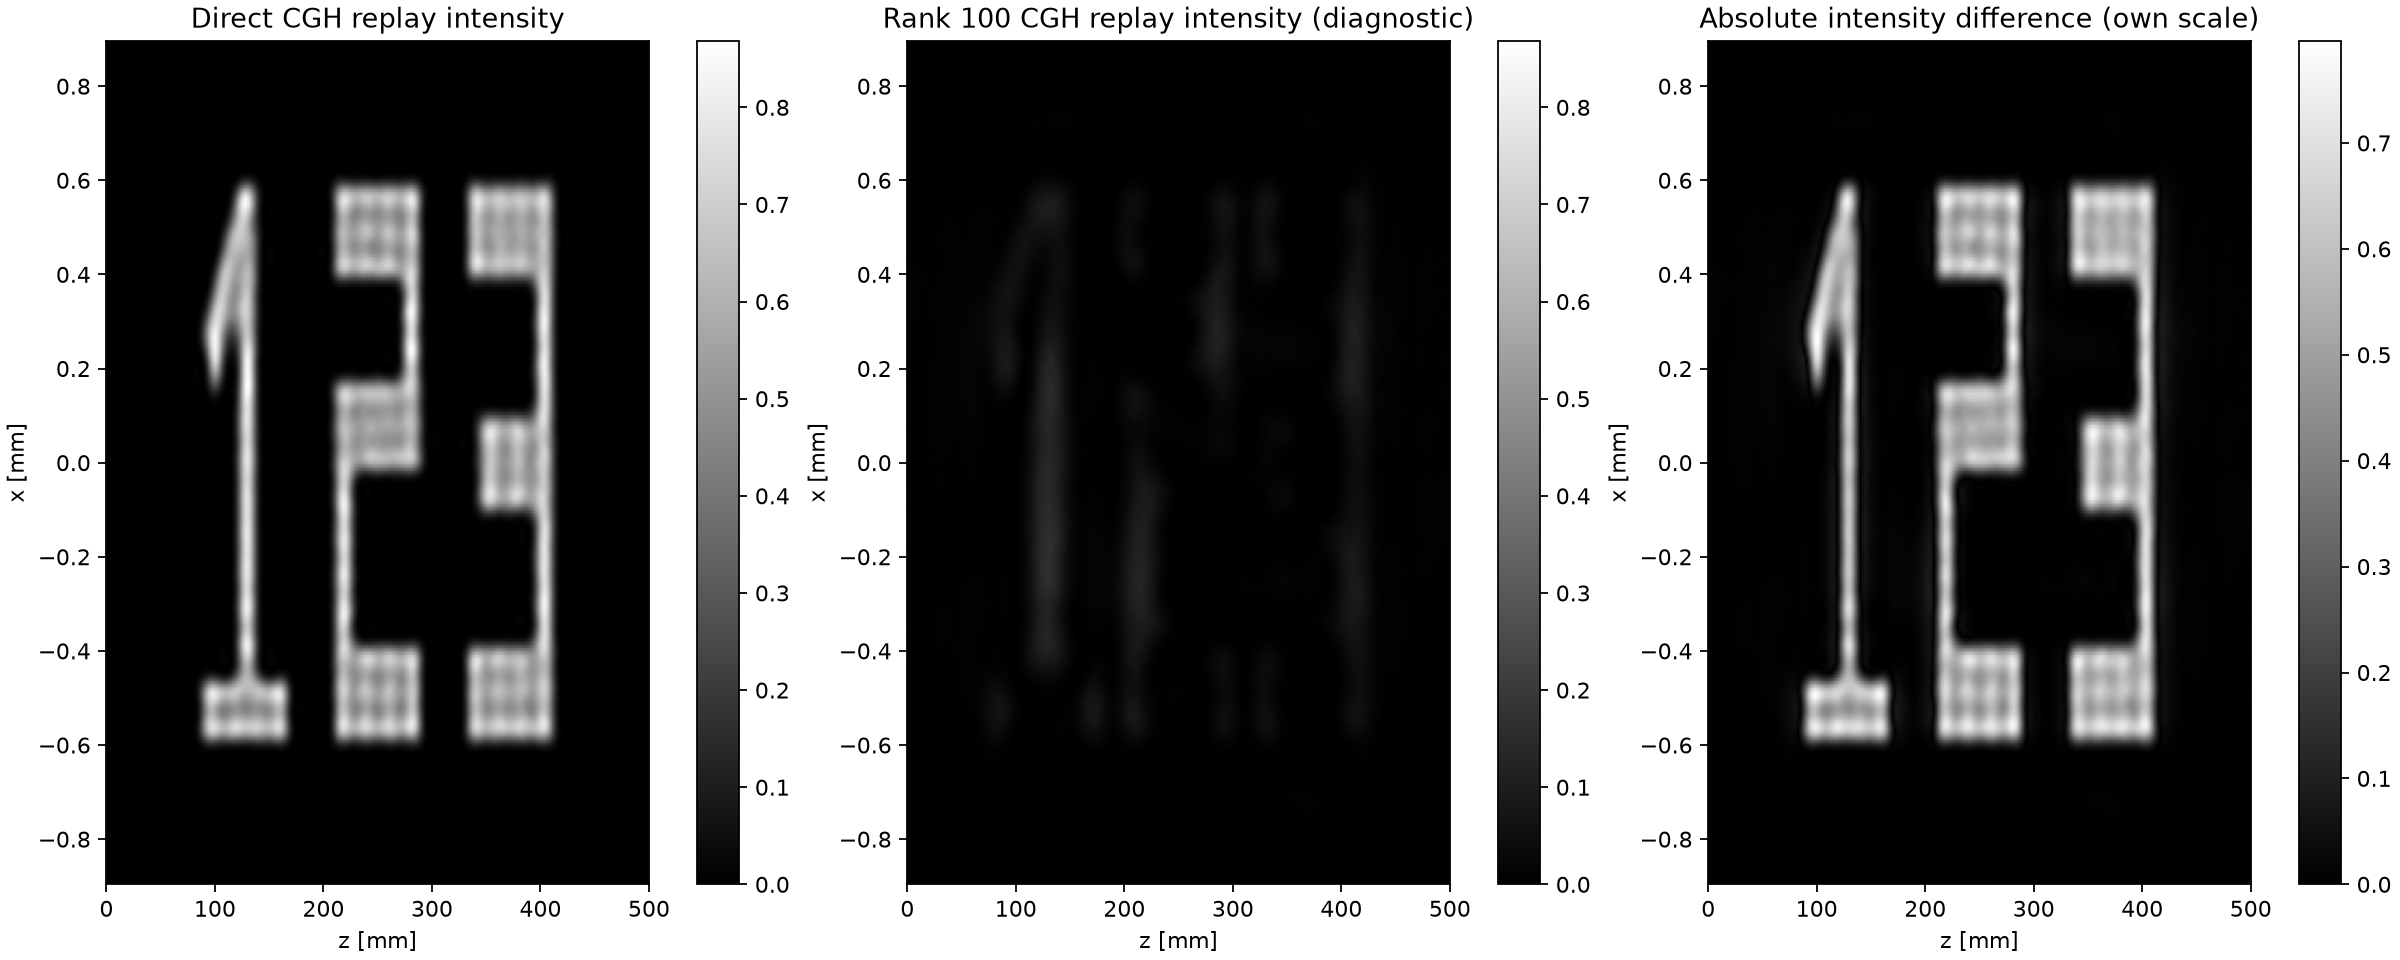

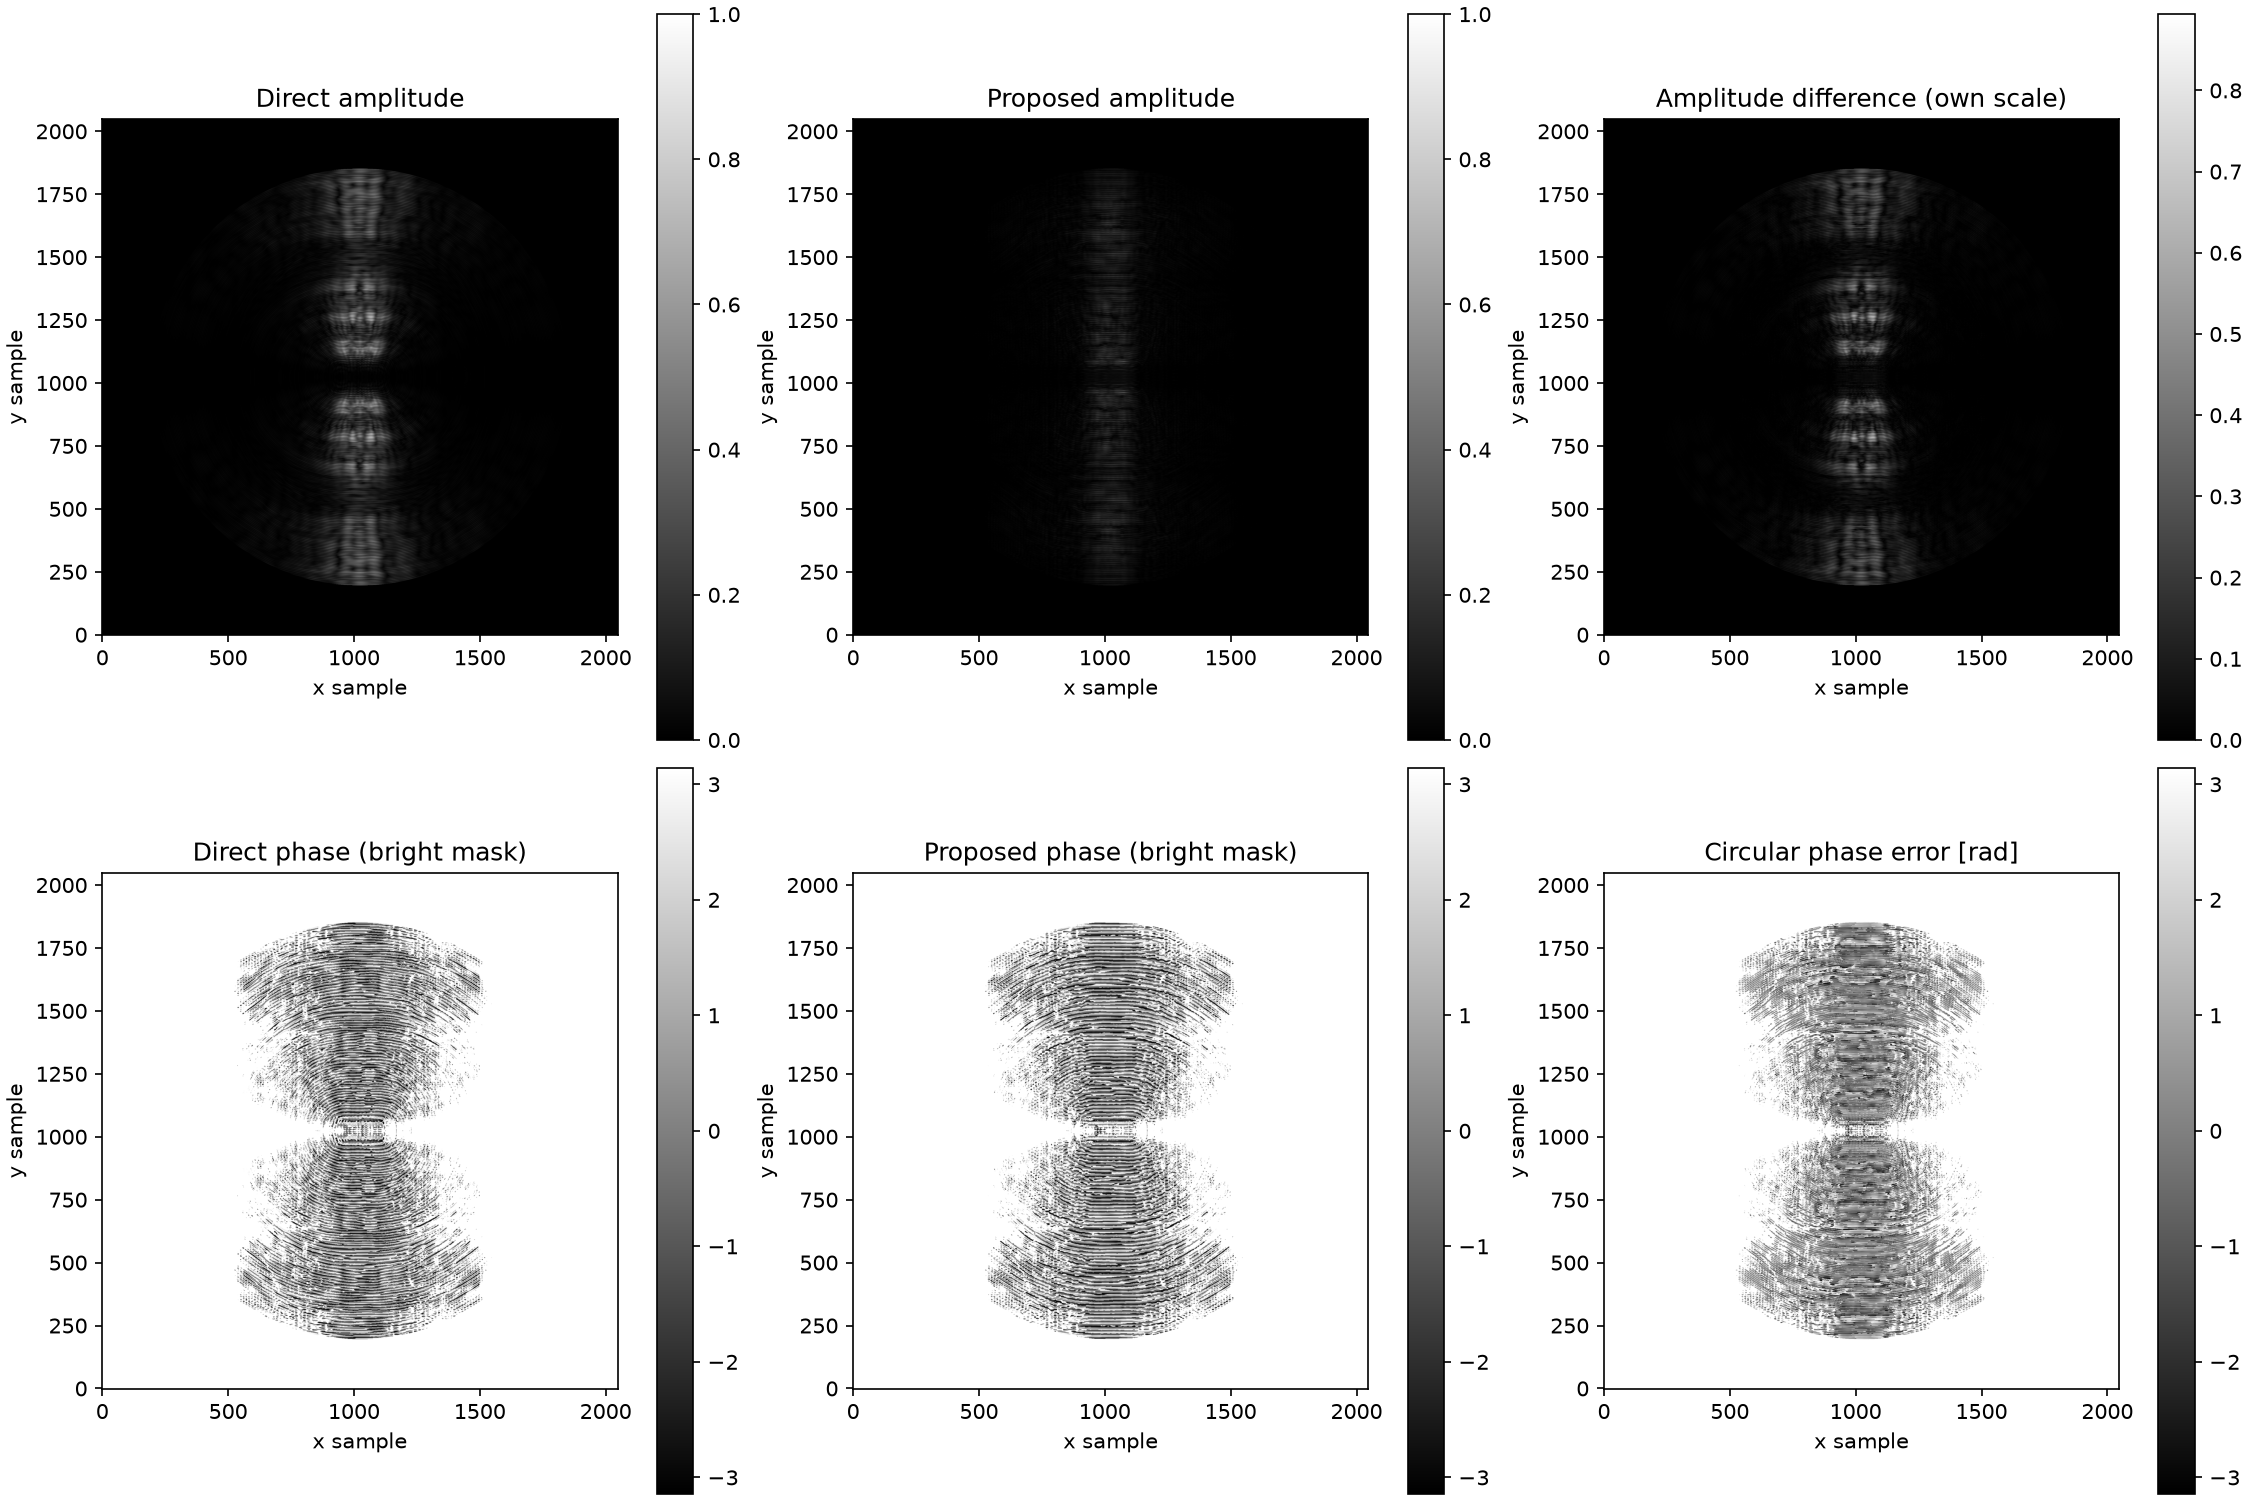

詳細: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank100\summary.json
8-bit位相マスク: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank100\proposed_cgh_8bit.png
拡大表示するランク: 200


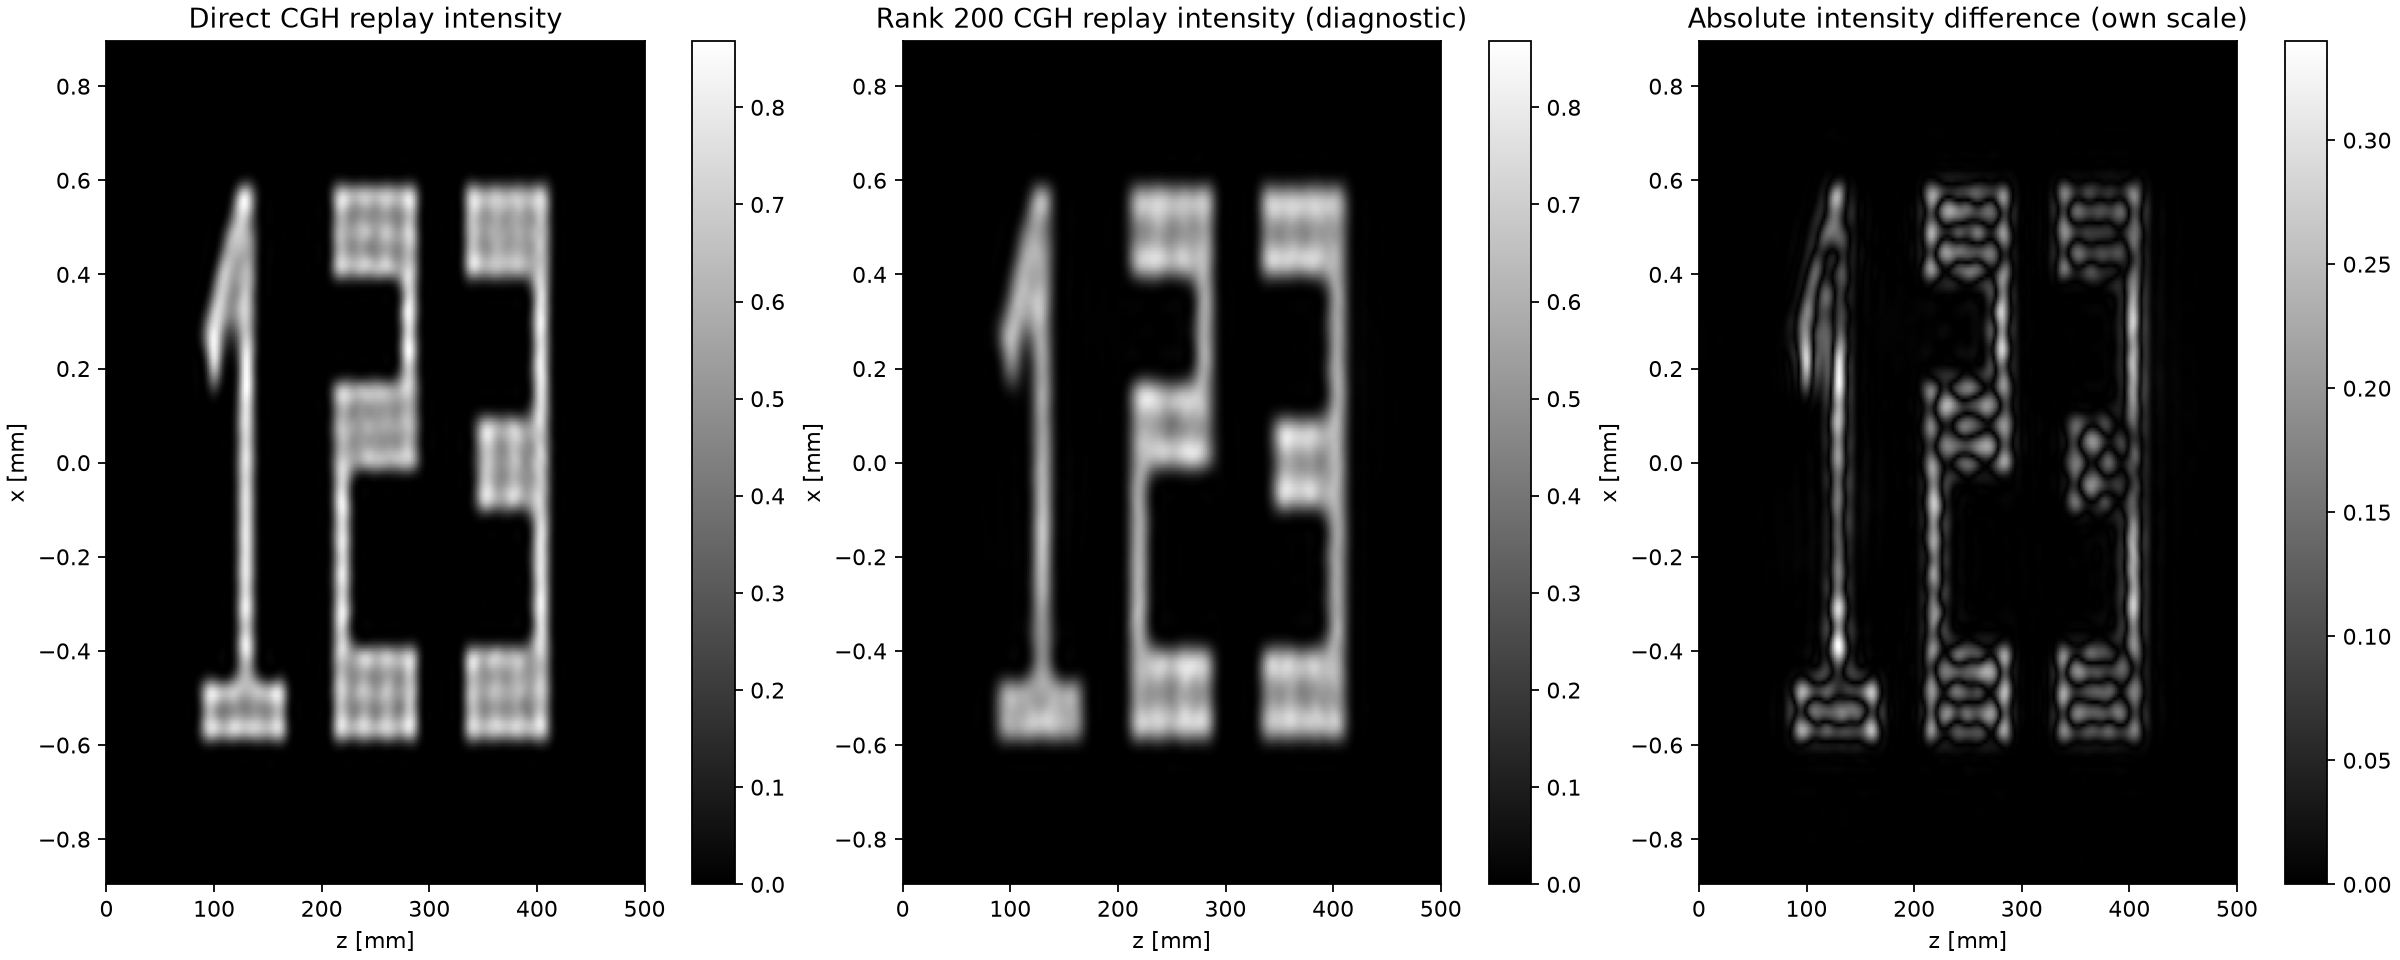

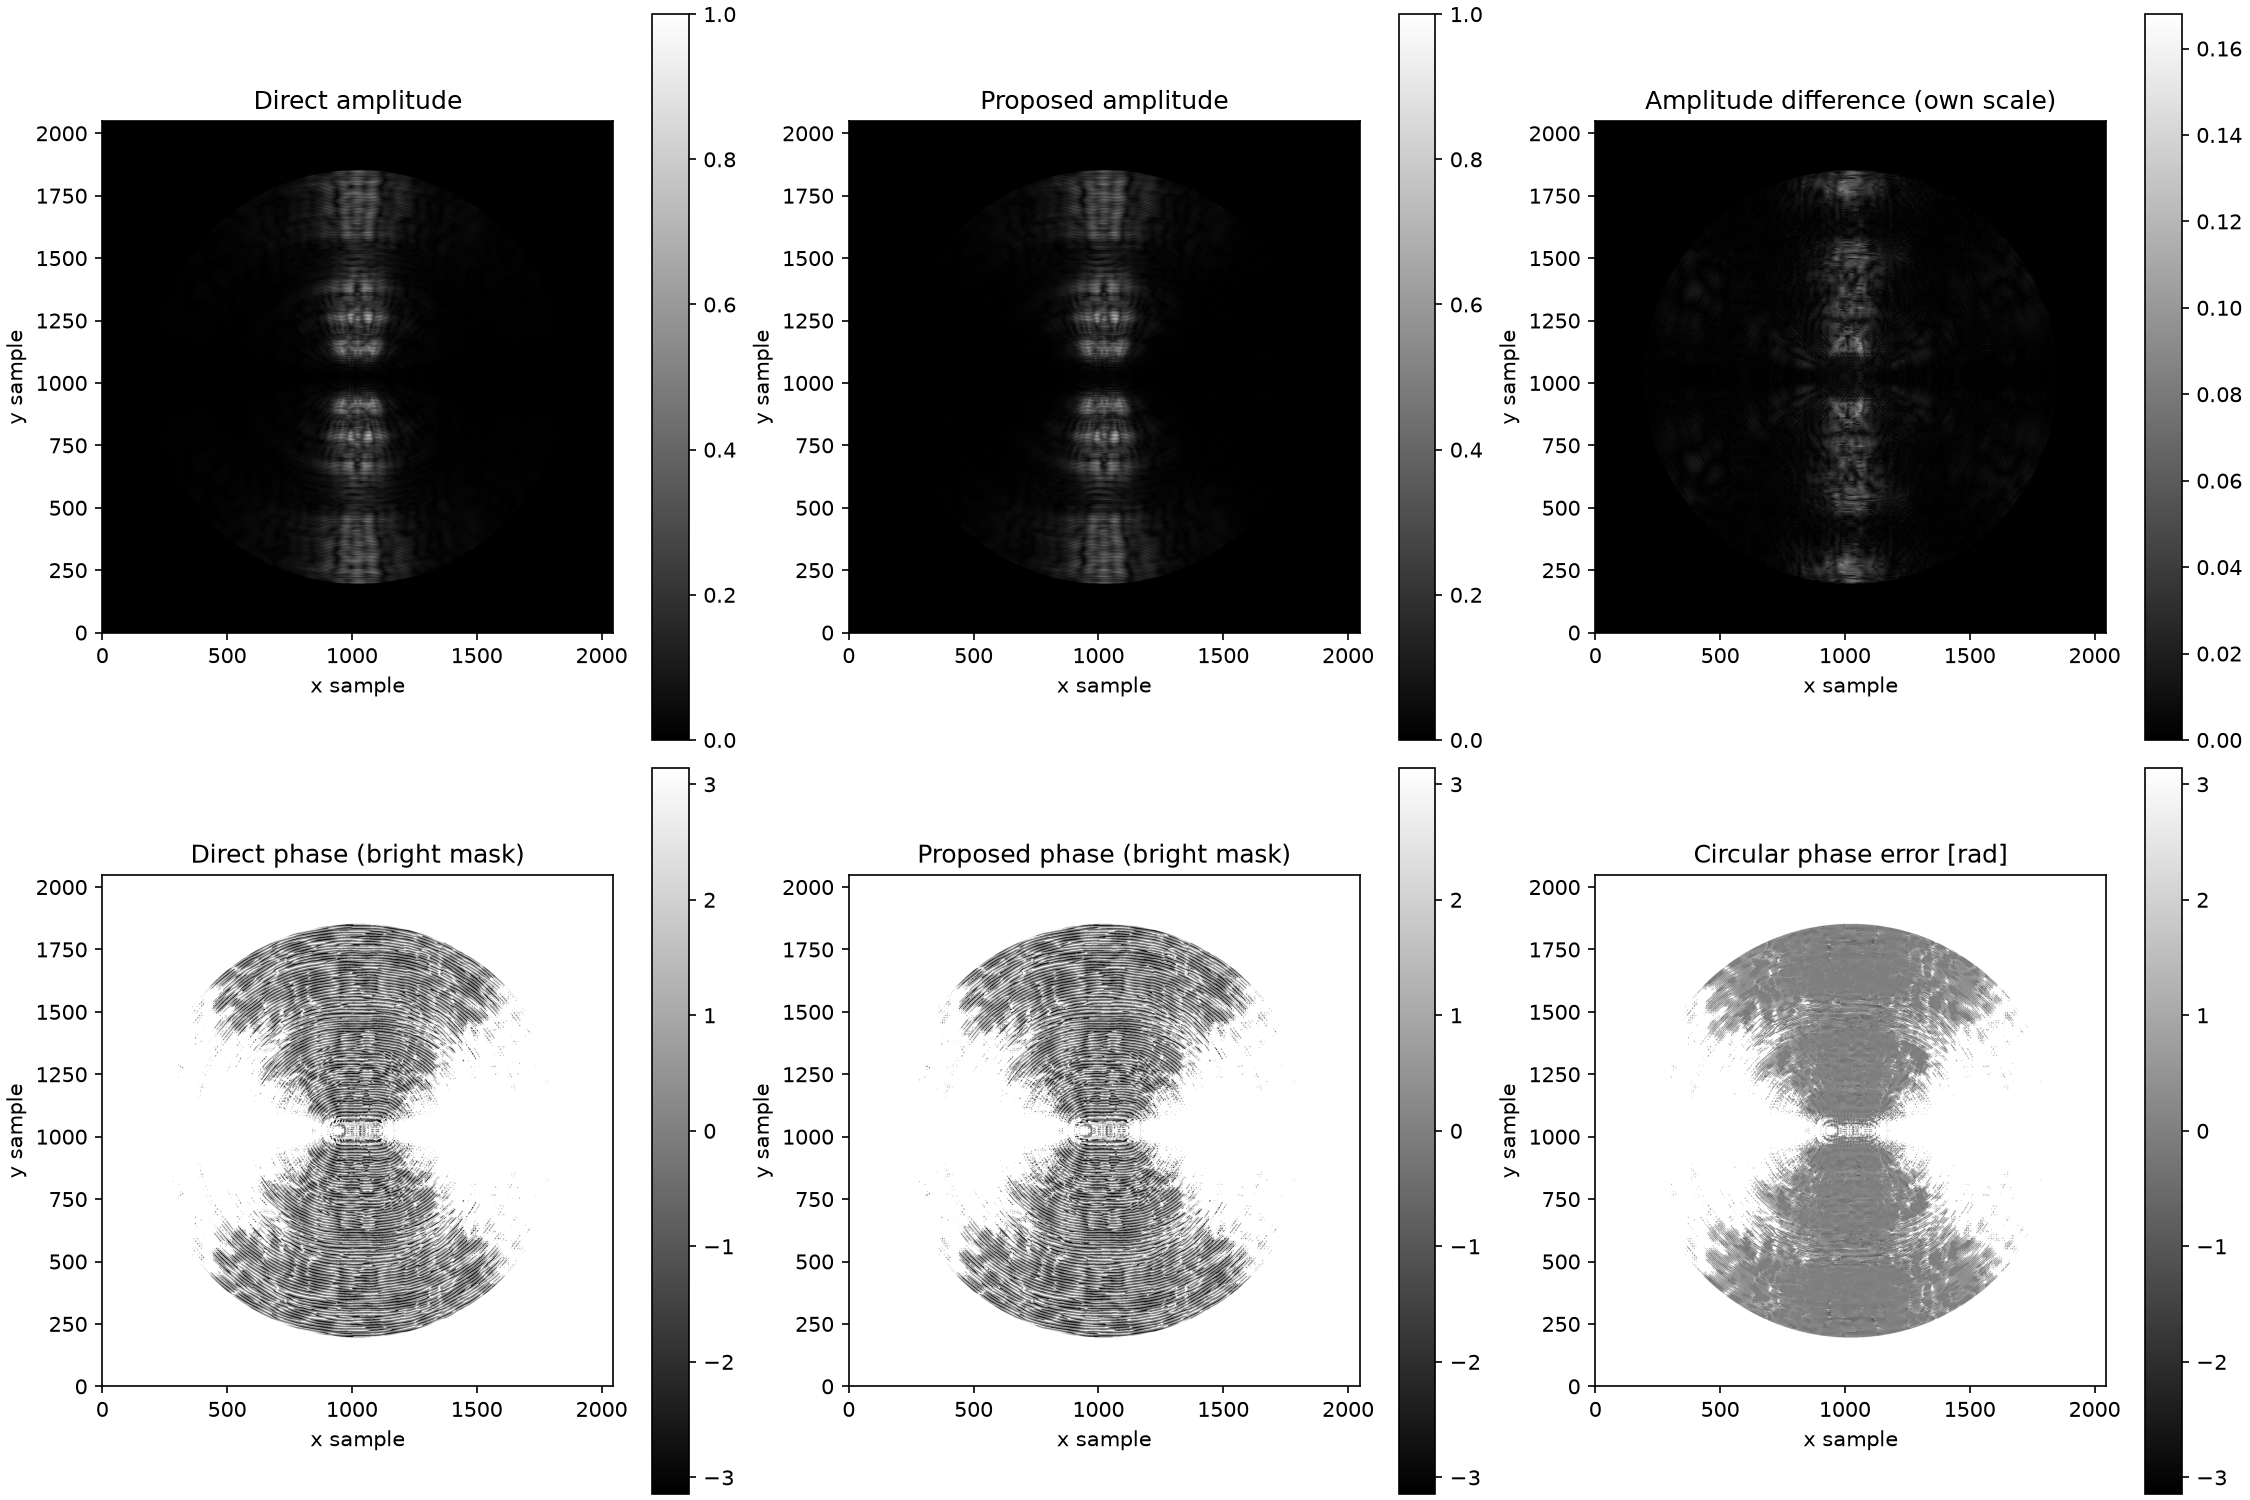

詳細: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank200\summary.json
8-bit位相マスク: C:\Users\kota-\Github\Project_new\research\lsh_digits123_low_rank_outputs_v2_extended\rank200\proposed_cgh_8bit.png
候補や測定条件を変更した場合はOUTPUT_DIRもv2などへ変更してください。


In [5]:
# 追加した50・100と200を個別に拡大する。差分は専用スケールと明記。
for selected_rank in (50, 100, 200):
    if selected_rank not in RANKS:
        continue
    case_dir = OUTPUT_DIR/f'rank{selected_rank}'
    print('拡大表示するランク:', selected_rank)
    display(Image(filename=str(case_dir/'cgh_sheet_comparison.png'), width=1200))
    display(Image(filename=str(case_dir/'initial_field_comparison.png'), width=1200))
    print('詳細:', (case_dir/'summary.json').resolve())
    print('8-bit位相マスク:', (case_dir/'proposed_cgh_8bit.png').resolve())
print('候補や測定条件を変更した場合はOUTPUT_DIRもv2などへ変更してください。')
